In [6]:
import os
from dotenv import load_dotenv
from langchain_groq import ChatGroq

In [3]:
load_dotenv()

True

In [43]:
groq_api_key = os.getenv("GROQ_API_KEY")
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    groq_api_key=groq_api_key,
)

response = llm.invoke("Write a poem about the beauty of nature in 2 sentence.")

print(response.content)

Morning dew clings to petals like whispered lullabies, and the sun paints the horizon with hues of amber and rose.  
Beneath the ancient canopy, rivers hum their timeless lull, reminding us that every leaf is a stanza in nature’s endless poem.


**bmi workflow**

In [21]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict
from typing_extensions import Annotated

In [26]:
# define state
class BMIState(TypedDict):
    weight:float
    height:float
    bmi:float
    category:str

In [23]:
def calculate_bmi(state:BMIState)->BMIState:
    weight = state["weight"]
    height = state["height"]
    bmi = weight / (height ** 2)
    state["bmi"] = round(bmi,2)
    return state

In [27]:
def label_bmi(state:BMIState)->BMIState:
    bmi = state["bmi"]
    if bmi < 18.5:
        state["category"] = "Underweight"
    elif 18.5 <= bmi < 24.9:
        state["category"] = "Normal weight"
    elif 25 <= bmi < 29.9:
        state["category"] = "Overweight"
    else:
        state["category"] = "Obesity"
    return state

In [31]:
graph=StateGraph(BMIState)

#add node
graph.add_node('calculate_bmi',calculate_bmi)
graph.add_node('label_bmi',label_bmi)
# add edge
graph.add_edge(START,'calculate_bmi')
graph.add_edge('calculate_bmi','label_bmi')
graph.add_edge('label_bmi',END)
# compile
workflow=graph.compile()
# execute
output_state=workflow.invoke({"weight":58,"height":1.73})
print(output_state)

{'weight': 58, 'height': 1.73, 'bmi': 19.38, 'category': 'Normal weight'}


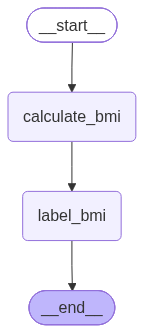

In [32]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

**simple llm workflow**

In [33]:
class LLMState(TypedDict):
    question:str
    answer:str

In [34]:
def llm_qa(state:LLMState)->LLMState:
    question = state["question"]
    prompt = f"Answer the following question: {question}"
    response = llm.invoke(prompt)
    state["answer"] = response.content
    return state

In [35]:
graph=StateGraph(LLMState)

graph.add_node('llm_qa',llm_qa)

graph.add_edge(START,'llm_qa')
graph.add_edge('llm_qa',END)

workflow=graph.compile()

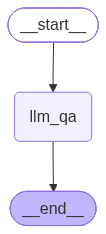

In [36]:
graph.compile()

In [42]:
output_state=workflow.invoke({"question":"who are you ?"})
print(output_state['answer'])

I’m ChatGPT, a large language model developed by OpenAI. I’m a virtual assistant designed to understand and generate human‑like text based on the prompts I receive.
